# Q3 - Classical baseline (LightGBM on HOG+LBP)

Results for `scripts/train_baseline.py`'s 24-config hyperparameter search. The script itself
does the training and logs every config to `experiments/log.csv`; this notebook loads the
saved artifacts (model, cached validation features, the log) and builds the figures/analysis
for the report - no training happens here, keeping with `notebooks/` being for analysis, not
duplicated pipeline logic.

**Test isolation:** everything below uses validation data only, same as `train_baseline.py` -
test is never read here either.

In [1]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, precision_recall_curve

PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"
FIGURES_DIR = PROJECT_ROOT / "docs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

CLASS_ORDER = ["Clear", "Crystals", "Other", "Precipitate"]
CLASS_COLORS = {
    "Clear": "#0072B2",
    "Crystals": "#D55E00",
    "Precipitate": "#E69F00",
    "Other": "#999999",
}
P_MIN = 0.30  # official primary metric threshold - see docs/primary_metric.md

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["figure.dpi"] = 100

In [2]:
model = joblib.load(PROJECT_ROOT / "experiments" / "models" / "baseline_lightgbm.joblib")

val_cache = np.load(DATA_DIR / "features_baseline" / "val_features.npz", allow_pickle=True)
X_val = val_cache["X"]

splits = pd.read_csv(DATA_DIR / "splits.csv")
val_df = splits[splits["split"] == "val"].reset_index(drop=True)
assert np.array_equal(val_cache["image_id"], val_df["image_id"].to_numpy())
y_val = val_df["label"].to_numpy()

print(f"model: {model.__class__.__name__}, val set: {len(y_val)} images")
print("best params:", model.get_params())

model: LGBMClassifier, val set: 2053 images
best params: {'boosting_type': 'gbdt', 'class_weight': 'balanced', 'colsample_bytree': 1.0, 'importance_type': 'split', 'learning_rate': 0.1, 'max_depth': -1, 'min_child_samples': 50, 'min_child_weight': 0.001, 'min_split_gain': 0.0, 'n_estimators': 200, 'n_jobs': None, 'num_leaves': 63, 'objective': 'multiclass', 'random_state': 42, 'reg_alpha': 0.0, 'reg_lambda': 0.0, 'subsample': 1.0, 'subsample_for_bin': 200000, 'subsample_freq': 0, 'verbosity': -1, 'feature_fraction': 0.6, 'bagging_fraction': 0.8, 'bagging_freq': 5}


In [3]:
print(type(model))
print(model)

<class 'lightgbm.sklearn.LGBMClassifier'>
LGBMClassifier(bagging_fraction=0.8, bagging_freq=5, class_weight='balanced',
               feature_fraction=0.6, min_child_samples=50, n_estimators=200,
               num_leaves=63, objective='multiclass', random_state=42,
               verbosity=-1)


In [4]:
# Read the model’s settings and what it learned

clf = model   # or model.named_steps["..."] if it's a Pipeline

print(clf.get_params())            # hyperparameters used
print("classes:", clf.classes_)    # label order, e.g. Clear, Crystals, Other, Precipitate
print("features:", clf.n_features_in_)
print("trees:", clf.booster_.num_trees())

{'boosting_type': 'gbdt', 'class_weight': 'balanced', 'colsample_bytree': 1.0, 'importance_type': 'split', 'learning_rate': 0.1, 'max_depth': -1, 'min_child_samples': 50, 'min_child_weight': 0.001, 'min_split_gain': 0.0, 'n_estimators': 200, 'n_jobs': None, 'num_leaves': 63, 'objective': 'multiclass', 'random_state': 42, 'reg_alpha': 0.0, 'reg_lambda': 0.0, 'subsample': 1.0, 'subsample_for_bin': 200000, 'subsample_freq': 0, 'verbosity': -1, 'feature_fraction': 0.6, 'bagging_fraction': 0.8, 'bagging_freq': 5}
classes: ['Clear' 'Crystals' 'Other' 'Precipitate']
features: 1924
trees: 800


In [5]:
# See which features matter most

names = getattr(clf, "feature_name_", [f"f{i}" for i in range(clf.n_features_in_)])
imp = pd.Series(clf.booster_.feature_importance(importance_type="gain"), index=names)
print(imp.sort_values(ascending=False).head(20))

Column_1816    8033.461318
Column_1826    4349.412824
Column_1866    3562.358791
Column_1856    1361.461776
Column_448     1220.713608
Column_1868    1132.207524
Column_871     1008.083634
Column_1763     963.269887
Column_1870     733.665268
Column_1159     627.683694
Column_640      552.508651
Column_1823     539.380888
Column_1873     516.515713
Column_1818     491.489581
Column_642      466.576261
Column_1546     464.021371
Column_1092     460.075244
Column_874      433.289722
Column_1573     410.790396
Column_1814     398.069455
dtype: float64


In [6]:
# Read the actual trees

trees = clf.booster_.trees_to_dataframe()
print(trees.head(20))                                    # first tree, node by node
print(trees.groupby("tree_index").size().describe())     # nodes per tree

    tree_index  node_depth node_index left_child right_child parent_index  \
0            0           1       0-S0       0-S1        0-S2          NaN   
1            0           2       0-S1       0-S4       0-S13         0-S0   
2            0           3       0-S4       0-S5        0-S8         0-S1   
3            0           4       0-S5       0-S7        0-L6         0-S4   
4            0           5       0-S7      0-S12       0-S16         0-S5   
5            0           6      0-S12      0-S15       0-L13         0-S7   
6            0           7      0-S15      0-S39       0-S24        0-S12   
7            0           8      0-S39       0-L0       0-S50        0-S15   
8            0           9       0-L0        NaN         NaN        0-S39   
9            0           9      0-S50      0-L40       0-S60        0-S39   
10           0          10      0-L40        NaN         NaN        0-S50   
11           0          10      0-S60      0-L51       0-S61        0-S50   

<Axes: >

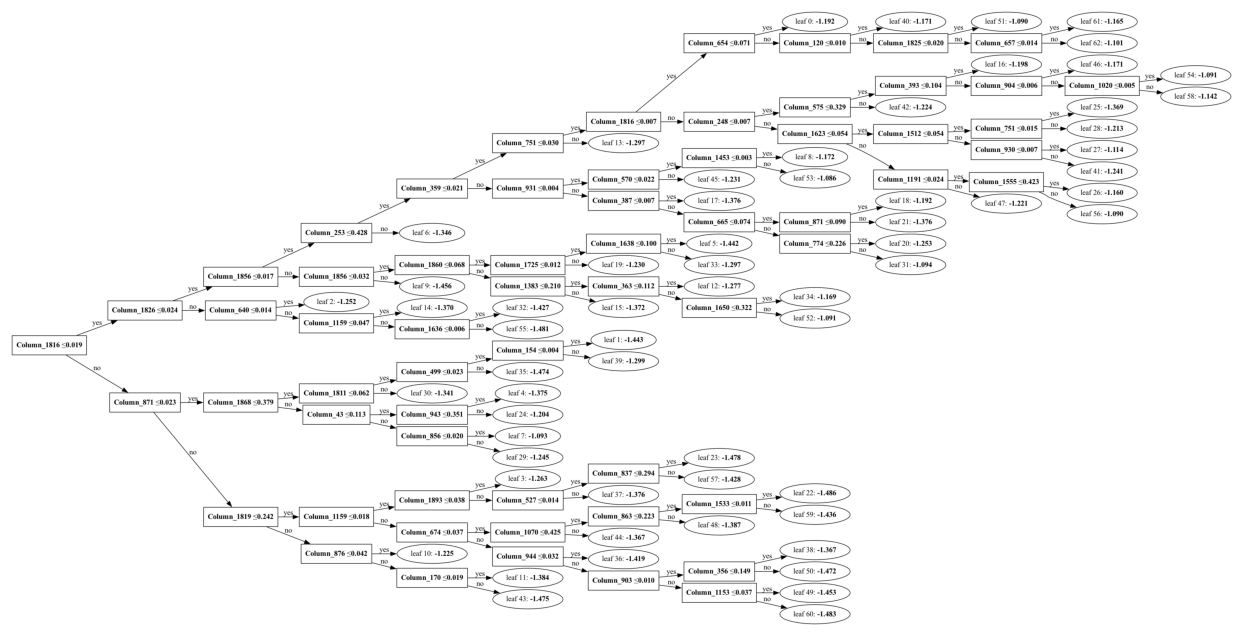

In [7]:
import lightgbm as lgb
lgb.plot_tree(clf.booster_, tree_index=0, figsize=(20, 8))

In [8]:
# Optional: save it as readable text
clf.booster_.save_model(str(PROJECT_ROOT / "experiments" / "models" / "baseline_lightgbm.txt"))

## Hyperparameter search

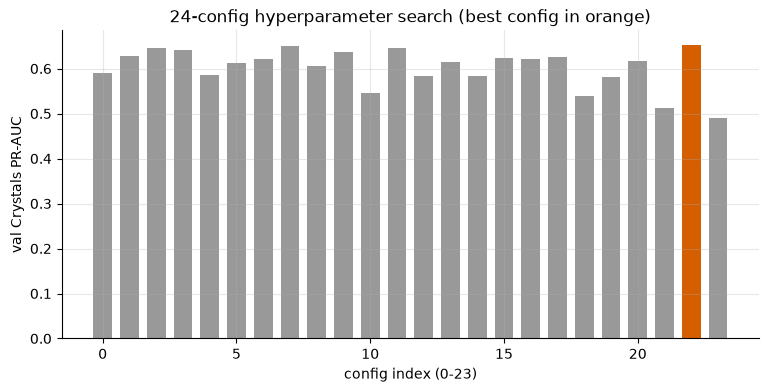

best: baseline_lgbm_022, crystals_pr_auc=0.652, train_time=28.9s
search range: 0.491 - 0.652


In [9]:
log = pd.read_csv(PROJECT_ROOT / "experiments" / "log.csv")
baseline_runs = log[log["model"] == "LightGBM (HOG+LBP)"].reset_index(drop=True)
metrics = baseline_runs["validation_metrics"].apply(json.loads)
baseline_runs["crystals_pr_auc"] = metrics.apply(lambda m: m["crystals_pr_auc"])
baseline_runs["train_time_s"] = metrics.apply(lambda m: m["train_time_s"])
best_idx = baseline_runs["crystals_pr_auc"].idxmax()

fig, ax = plt.subplots(figsize=(9, 4))
colors = ["#D55E00" if i == best_idx else "#999999" for i in range(len(baseline_runs))]
ax.bar(range(len(baseline_runs)), baseline_runs["crystals_pr_auc"], color=colors, width=0.7)
ax.set_xlabel("config index (0-23)")
ax.set_ylabel("val Crystals PR-AUC")
ax.set_title("24-config hyperparameter search (best config in orange)")
fig.savefig(FIGURES_DIR / "q3_baseline_search.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"best: {baseline_runs.loc[best_idx, 'id']}, "
      f"crystals_pr_auc={baseline_runs.loc[best_idx, 'crystals_pr_auc']:.3f}, "
      f"train_time={baseline_runs.loc[best_idx, 'train_time_s']:.1f}s")
print(f"search range: {baseline_runs['crystals_pr_auc'].min():.3f} - "
      f"{baseline_runs['crystals_pr_auc'].max():.3f}")

## Confusion matrix (default threshold)

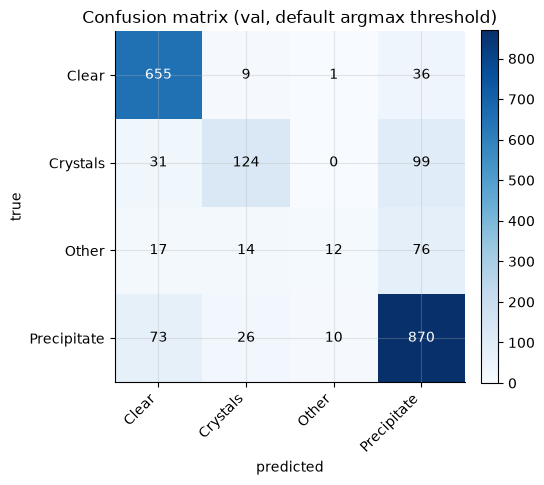

,Clear,Crystals,Other,Precipitate
Clear,655,9,1,36
Crystals,31,124,0,99
Other,17,14,12,76
Precipitate,73,26,10,870


In [10]:
preds = model.predict(X_val)
cm = confusion_matrix(y_val, preds, labels=CLASS_ORDER)

fig, ax = plt.subplots(figsize=(5.5, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(4)); ax.set_xticklabels(CLASS_ORDER, rotation=45, ha="right")
ax.set_yticks(range(4)); ax.set_yticklabels(CLASS_ORDER)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("Confusion matrix (val, default argmax threshold)")
for i in range(4):
    for j in range(4):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", color=color, fontsize=10)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "q3_baseline_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

pd.DataFrame(cm, index=CLASS_ORDER, columns=CLASS_ORDER)

## PR curve for Crystals, with P_MIN=0.30 and P_MIN=0.25 marked

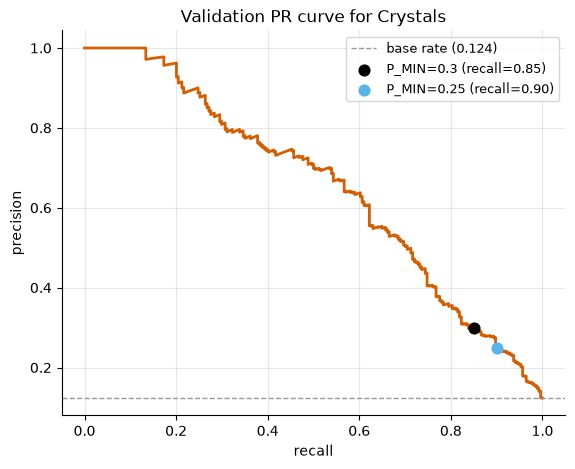

In [11]:
proba = model.predict_proba(X_val)
crystals_col = list(model.classes_).index("Crystals")
y_bin = (y_val == "Crystals").astype(int)
precision, recall, thresholds = precision_recall_curve(y_bin, proba[:, crystals_col])

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(recall, precision, color=CLASS_COLORS["Crystals"], lw=2)
ax.axhline(y_bin.mean(), color="#999999", ls="--", lw=1, label=f"base rate ({y_bin.mean():.3f})")

for target_p, marker_color in [(0.30, "#000000"), (0.25, "#56B4E9")]:
    diffs = np.abs(precision[:-1] - target_p)
    idx = np.argmin(diffs)
    ax.scatter(recall[idx], precision[idx], color=marker_color, zorder=5, s=60,
               label=f"P_MIN={target_p} (recall={recall[idx]:.2f})")

ax.set_xlabel("recall"); ax.set_ylabel("precision")
ax.set_title("Validation PR curve for Crystals")
ax.legend(loc="upper right", fontsize=9)
fig.savefig(FIGURES_DIR / "q3_baseline_pr_curve.png", dpi=150, bbox_inches="tight")
plt.show()

## P_MIN=0.30 (official) vs P_MIN=0.25 (comparison only)

`P_MIN=0.30` is the fixed primary metric threshold (`docs/primary_metric.md`) - this section
does not change that decision, it's a sensitivity check to see the actual difference the choice
makes, computed exactly (not read off the printed curve) from the saved model and cached
validation features.

In [12]:
def metrics_at_precision(target_p: float) -> dict:
    diffs = np.abs(precision[:-1] - target_p)
    idx = np.argmin(diffs)
    thr = thresholds[idx]
    pred = (proba[:, crystals_col] >= thr).astype(int)
    tp = int(((pred == 1) & (y_bin == 1)).sum())
    fp = int(((pred == 1) & (y_bin == 0)).sum())
    fn = int(((pred == 0) & (y_bin == 1)).sum())
    tn = int(((pred == 0) & (y_bin == 0)).sum())
    return {
        "P_MIN": target_p, "actual_precision": round(precision[idx], 3),
        "recall": round(recall[idx], 3), "FN_rate_%": round(fn / (fn + tp) * 100, 1),
        "FP_rate_%": round(fp / (fp + tn) * 100, 1), "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    }

comparison = pd.DataFrame([metrics_at_precision(0.30), metrics_at_precision(0.25)])
comparison

,P_MIN,actual_precision,recall,FN_rate_%,FP_rate_%,TP,FP,FN,TN
0,0.30,0.30,0.850,15.0,28.0,216,504,38,1295
1,0.25,0.25,0.902,9.8,38.2,229,687,25,1112


**Reading this:** moving from `P_MIN=0.30` to `0.25` recovers some recall (85% -> 90%, FN rate
15% -> 9.8%) but costs real precision - the false-positive rate rises from 28% to 38%, meaning
a meaningfully larger share of flagged drops are false alarms. `0.30` stays the official
threshold; this comparison is kept here as the documented evidence for why.